<a href="https://colab.research.google.com/github/kvikaee/machine-learning/blob/main/ML_5_%D0%9A%D0%BE%D1%88%D1%83%D1%80%D0%B8%D0%BD%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Нейронные сети

Лабораторная работа посвящена нейронным сетям.

Если кратко, то нейронная сеть - это серия последовательных преобразований, применяемым к входным данным с целью получить выходные данные. Основными операциями являются сложение, умножение, а также применение нелинейных преобразований вроде взятия экспоненты.

С помощью нейронных сетей сейчас успешно решается огромное количество задач.

Самой простой нейронной сетью можно назвать старую добрую линейную регресиию. Чуть более сложной - логистическую регрессию. По сути, логистическая регрессия = линейная регрессия + сигмоида в качестве функции активации.

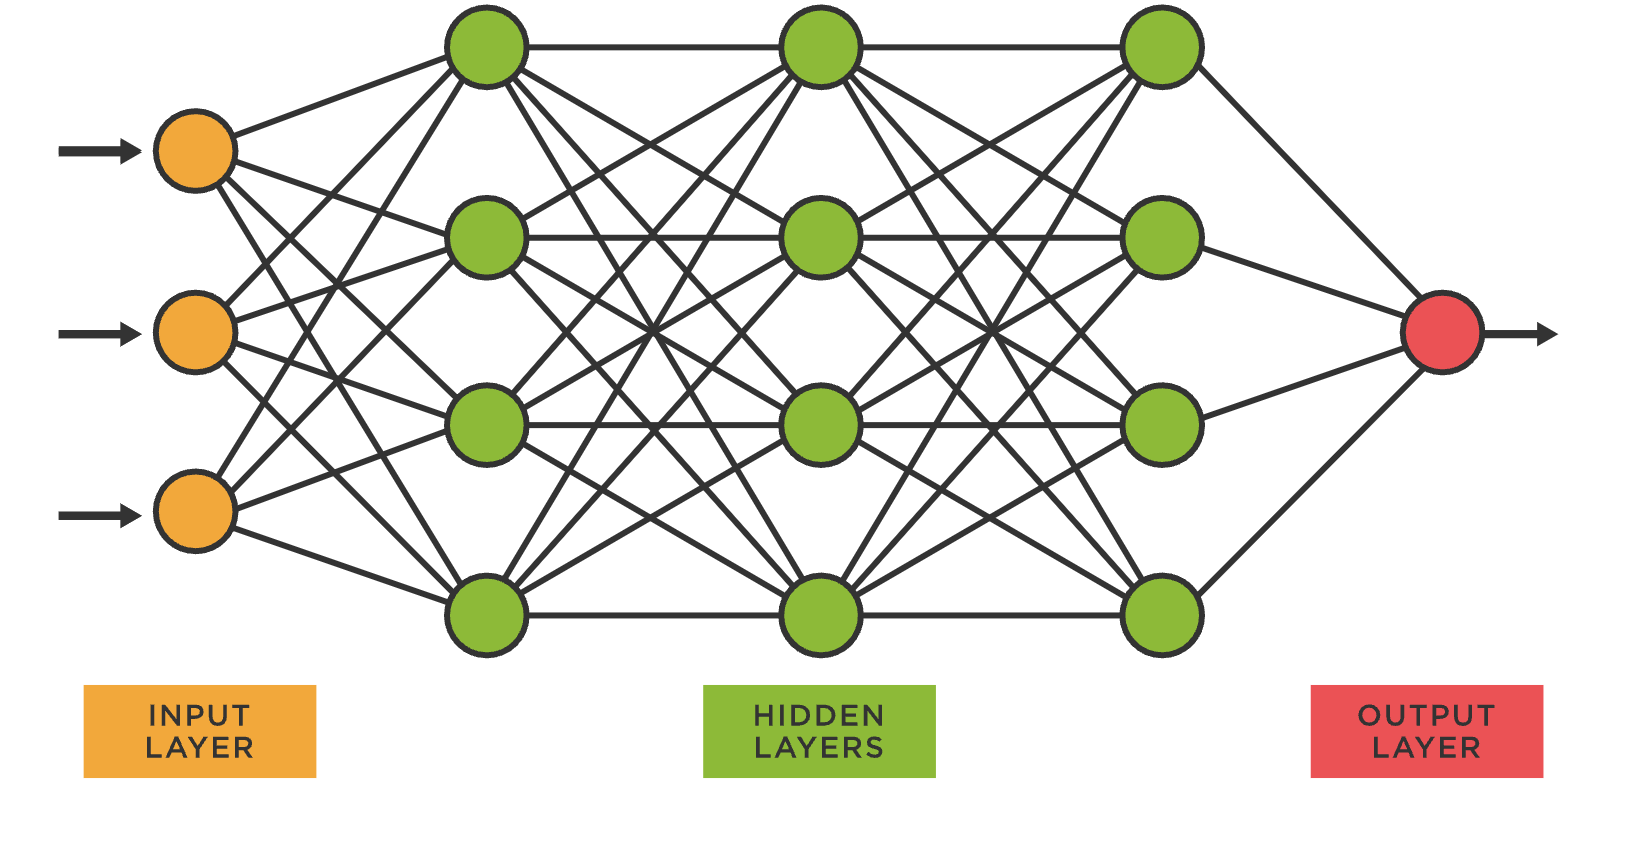

Нейронная сеть состоит из последовательных слоев, каждый слой состоит из нейронов. Входной слой - это исходные данные, выходной - результат, получающийся в результате прямого прохода (forward pass) по нейронной сети.

Каждый нейрон представляет из себя функцию. Мы будем рассматривать нейроны вида $Activation(XW + b)$, где $X$ - входные данные, $W$ и $b$ - настраиваемые параметры сети, $Activation()$ - какое-либо преобразование, совершаемое над результатом $XW + b$. В самом простом случае $Activation()$ == $Identity()$.

Обучаются нейронные сети с помощью алгоритма обратного распространения ошибки (backpropagation). То есть после преобразований мы получаем от нейронной сети какой-то выход, затем с помощью функции потерь оцениваем, насколько он далёк от того, что хотелось бы получить, а потом с помощью градиентного спуска корректируем настраиваемые параметры сети так, чтобы она выдавала более качественные ответы.

При обратном распространении мы идем по сети из конца в начало. Для расчета градиентов на каждом шаге применяется правило цепочки: $\frac{{df}}{{dx}} = \frac{{df}}{{dg}} \cdot \frac{{dg}}{{dx}}$

Выполнять задания лабораторной работы можно последовательно, однако рекомендуется сначала реализовать блок "Операции над матрицами", затем MSE из блока "Функции потерь", после  Identity из блока "Функции активации", затем полносвязную нейронную сеть в её первом приближении. Потом можно доделать все оставшиеся пункты работы.

Дополнительные материалы:

1. Книга [Грокаем глубокое обучение](https://library.tsilikin.ru/%D0%A2%D0%B5%D1%85%D0%BD%D0%B8%D0%BA%D0%B0/%D0%98%D0%BD%D1%84%D0%BE%D1%80%D0%BC%D0%B0%D1%86%D0%B8%D0%BE%D0%BD%D0%BD%D1%8B%D0%B5%20%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D0%B8%D0%B8/AI/%D0%9D%D0%B5%D0%B9%D1%80%D0%BE%D0%BD%D0%BD%D1%8B%D0%B5%20%D1%81%D0%B5%D1%82%D0%B8/%D0%93%D1%80%D0%BE%D0%BA%D0%B0%D0%B5%D0%BC%20%D0%B3%D0%BB%D1%83%D0%B1%D0%BE%D0%BA%D0%BE%D0%B5%20%D0%BE%D0%B1%D1%83%D1%87%D0%B5%D0%BD%D0%B8%D0%B5.pdf), где нейронные сети разбираются буквально на пальцах

2. Онлайн-курс [Введение в искусственные нейронные сети](https://stepik.org/course/100076/syllabus?auth=login) от ОмГТУ

## Операции над матрицами

In [ ]:
from copy import deepcopy
import numpy as np

Нейронные сети работают с числами, представленными в виде многомерных массивов данных.

Частным случаем таких массивов являются двумерные матрицы. Вспомним азы математики и реализуем следующие функции:

1. Умножение матрицы на скаляр

2. Сложение матриц

3. Транспонирование матрицы

4. Умножение матриц. Умножать матрицы можно, если число столбцов первой матрицы равно числу строк второй матрицы

При реализации используйте функции и методы для работы со списками, циклы, а также списковые включения. NumPy можно использовать только для проверки корректности работы вашего кода.

1

In [ ]:
def validate_matrix(matrix):
    assert len(matrix) > 0, "Входная матрица не должна быть пустой"
    assert isinstance(matrix, list), "Входная матрица должна быть представлена списком"
    assert all(isinstance(row, list) for row in matrix), "Каждая строка в матрице должна быть списком"
    assert all(len(row) == len(matrix[0]) for row in matrix), "Все строки в матрице должны быть одинаковой длины"


def scalar_multiplication(matrix: list[list[float]], scalar: float,
                          copy: bool = True) -> list[list[float]] | None:
    validate_matrix(matrix)
    if copy:
        return [[elem * scalar for elem in row] for row in matrix]
    for i in range(len(matrix)):
        for j in range(len(matrix[i])):
            matrix[i][j] *= scalar
    return None


def matrix_addition(matrix1: list[list[float]],
                    matrix2: list[list[float]]) -> list[list[float]]:
    validate_matrix(matrix1)
    validate_matrix(matrix2)
    assert len(matrix1) == len(matrix2) and len(matrix1[0]) == len(matrix2[0]), \
        "Матрицы должны иметь одинаковые размеры"
    return [[matrix1[i][j] + matrix2[i][j] for j in range(len(matrix1[0]))]
            for i in range(len(matrix1))]


def matrix_transposition(matrix: list[list[float]]) -> list[list[float]]:
    validate_matrix(matrix)
    return [[matrix[i][j] for i in range(len(matrix))]
            for j in range(len(matrix[0]))]


def matrix_multiplication(matrix1: list[list[float]],
                          matrix2: list[list[float]]) -> list[list[float]]:
    validate_matrix(matrix1)
    validate_matrix(matrix2)
    assert len(matrix1[0]) == len(matrix2), \
        "Число столбцов первой матрицы должно равняться числу строк второй матрицы"
    rows1 = len(matrix1)
    cols2 = len(matrix2[0])
    cols1 = len(matrix1[0])
    return [[sum(matrix1[i][k] * matrix2[k][j] for k in range(cols1))
             for j in range(cols2)]
            for i in range(rows1)]

In [ ]:
def print_matrix(matrix):
    for row in matrix:
        print(row)


matrix1 = [[1, 2, 3],
           [4, 5, 6],
           [7, 8, 9]]

matrix2 = [[9, 8, 7],
           [6, 5, 4],
           [3, 2, 1]]

print("Умножение на скаляр:")
print_matrix(scalar_multiplication(matrix1, 2))
print()

print("Сложение матриц:")
print_matrix(matrix_addition(matrix1, matrix2))
print()

print("Произведение матриц:")
print_matrix(matrix_multiplication(matrix1, matrix2))
print()

print("Транспонирование матрицы:")
print_matrix(matrix_transposition(matrix1))
print()

Умножение на скаляр:
[2, 4, 6]
[8, 10, 12]
[14, 16, 18]

Сложение матриц:
[10, 10, 10]
[10, 10, 10]
[10, 10, 10]

Произведение матриц:
[30, 24, 18]
[84, 69, 54]
[138, 114, 90]

Транспонирование матрицы:
[1, 4, 7]
[2, 5, 8]
[3, 6, 9]



Теперь, когда мы вспомнили, как считать, порадуемся, что в NumPy всё уже давно реализовано за нас. В дальнейшей работе будем использовать функционал библиотеки NumPy.

In [ ]:
matrix1 = np.array([[1, 2, 3],
                    [4, 5, 6],
                    [7, 8, 9]])

matrix2 = np.array([[9, 8, 7],
                    [6, 5, 4],
                    [3, 2, 1]])

print("Умножение на скаляр:")
print_matrix(matrix1 * 2)
print()

print("Сложение матриц:")
print_matrix(matrix1 + matrix2)
print()

print("Произведение матриц:")
print_matrix(matrix1 @ matrix2)
print()

print("Транспонирование матрицы:")
print_matrix(matrix1.T)
print()

Умножение на скаляр:
[2 4 6]
[ 8 10 12]
[14 16 18]

Сложение матриц:
[10 10 10]
[10 10 10]
[10 10 10]

Произведение матриц:
[30 24 18]
[84 69 54]
[138 114  90]

Транспонирование матрицы:
[1 4 7]
[2 5 8]
[3 6 9]



## Функции активации (3 балла)

In [ ]:
from abc import ABC, abstractmethod
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

Функции активации применяются "поверх" выхода какого-либо слоя, добавляя нелинейность.

Самая базовая функция активации - пороговая (именнно так устроены нейроны в человеческом мозге), но с точки зрения машинного обучения подобная функция неудобна, так как её тяжело дифференцировать, а значить проблематично применить алгоритм обратного распрострянения ошибки через градиентный спуск. Поэтому используют дифференцируемые аналоги.

3

In [ ]:
class ActivationFunction(ABC):
    @abstractmethod
    def __call__(self, x: np.ndarray) -> np.ndarray:
        """
        Применяет функцию активации к входным значениям.

        Параметры:
        - x: numpy.ndarray, входные значения

        Возвращает:
        - activation: numpy.ndarray, значение активации
        """
        pass

    @abstractmethod
    def grad(self, x: np.ndarray) -> np.ndarray:
        """
        Вычисляет градиент активационной функции по отношению к входным значениям.

        Параметры:
        - x: numpy.ndarray, входные значения

        Возвращает:
        - gradient: numpy.ndarray, градиент активационной функции
        """
        pass

### Identity

Самая простая функция активации - это её отсутствие, то есть идентичность.

$ Identity(x) = x $

$ Identity'(x) = \frac{d}{dx} Identity(x) = 1 $


Так как для каждого слоя выходное значение линейно, то они образуют линейную комбинацию, результатом которой является линейная функция. То есть если в сети присутствуют функции активации только вида Identity, то финальная функция активации на последнем слое зависит только от входных значений на первом слое. А это значит, что любое количество слоев может быть заменено всего одним слоем, и, следовательно, нет смысла создавать многослойную сеть.

In [ ]:
class Identity(ActivationFunction):
    def __call__(self, x: np.ndarray) -> np.ndarray:
        return x

    def grad(self, x: np.ndarray) -> np.ndarray:
        return np.ones_like(x)

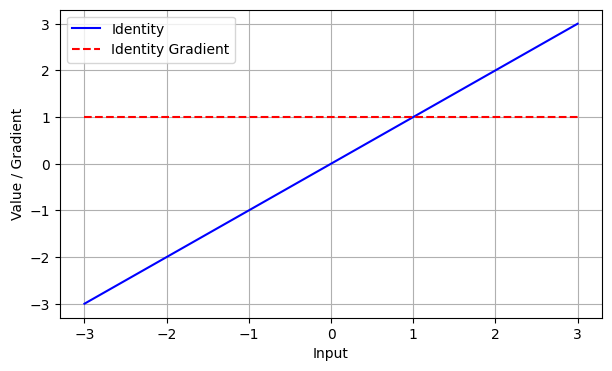

In [ ]:
x_range = np.linspace(-3, 3, 1000)

identity = Identity()
values = identity(x_range)
gradient = identity.grad(x_range)

plt.figure(figsize=(7, 4))
plt.plot(x_range, values, label='Identity', c='b')
plt.plot(x_range, gradient, label='Identity Gradient', linestyle='--', c='r')
plt.ylabel('Value / Gradient')
plt.xlabel('Input')
plt.legend()
plt.grid(True)
plt.show()

### Sigmoid

Функция активации Sigmoid - это нелинейная функция, которая преобразует входное значение в диапазон от 0 до 1. Преименяется в задачах бинарной классификации, часто используется на последнем слое нейронной сети. Функция определяется следующим образом:

$
\sigma(x) = \frac{1}{1 + e^{-x}}
$

Самостоятельно рассчитайте градиент функции.


Основной недостаток сигмоиды - проблема затухающих градиентов.

При обратном распространении ошибки в глубоких нейронных сетях могут возникать проблемы с затуханием градиентов из-за плато сигмоидальной функции на концах (см. график функции).

In [ ]:
class Sigmoid(ActivationFunction):
    def __call__(self, x: np.ndarray) -> np.ndarray:
        return 1.0 / (1.0 + np.exp(-x))

    def grad(self, x: np.ndarray) -> np.ndarray:
        s = self(x)
        return s * (1.0 - s)

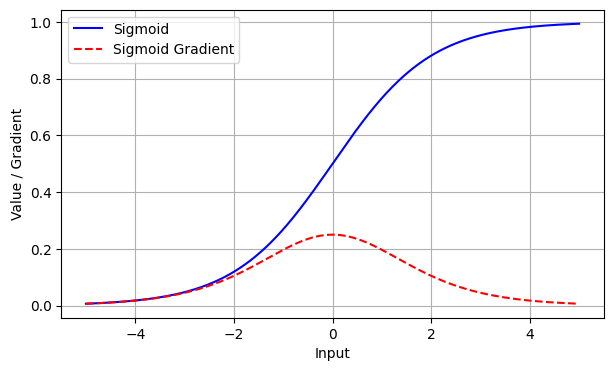

In [ ]:
x_range = np.linspace(-5, 5, 1000)

sigmoid = Sigmoid()
values = sigmoid(x_range)
gradient = sigmoid.grad(x_range)

plt.figure(figsize=(7, 4))
plt.plot(x_range, values, label='Sigmoid', c='b')
plt.plot(x_range, gradient, label='Sigmoid Gradient', linestyle='--', c='r')
plt.ylabel('Value / Gradient')
plt.xlabel('Input')
plt.legend()
plt.grid(True)
plt.show()

Сверим свою реализацию с реализацией из PyTorch.

In [ ]:
input = np.array([-2, 8, -5, 0.2, 0.1, 3, 7])

custom_output = Sigmoid()(input)
torch_output = F.sigmoid(torch.tensor(input)).numpy()

print("Custom Sigmoid Output:")
print(custom_output)
print()
print("PyTorch Sigmoid Output:")
print(torch_output)

assert np.allclose(custom_output, torch_output)

Custom Sigmoid Output:
[0.11920292 0.99966465 0.00669285 0.549834   0.52497919 0.95257413
 0.99908895]

PyTorch Sigmoid Output:
[0.11920292 0.99966465 0.00669285 0.549834   0.52497919 0.95257413
 0.99908895]


### ReLU

Функция активации ReLU (Rectified Linear Unit) представляет собой простую нелинейную функцию, которая определяется следующим образом:

$
\text{ReLU}(x) = \max(0, x)
$

$
\text{ReLU}'(x) = \begin{cases} 1, & \text{если } x > 0 \\ 0, & \text{если } x \leq 0 \end{cases}
$


**Возможные преимущества ReLU:**

1. Вычисление ReLU очень простое и дешевое с вычислительной точки зрения

2. Обычно приводит к разреженным активациям в нейронной сети, что помогает уменьшить переобучение и улучшить обобщающую способность модели

3. ReLU не подвержена проблеме исчезающего градиента, которая может возникнуть при использовании сигмоидной функции активации

**Недостатки ReLU:**

1. Некоторые нейроны могут "умереть" и всегда выдавать ноль, из-за чего они перестают обновляться в процессе обучения. Это происходит, когда весовые суммы нейронов входят в область отрицательных значений и не активируются. В результате обучения такие нейроны могут оставаться неактивными и не приносить пользы

2. ReLU не центрирована относительно нуля

In [ ]:
class ReLU(ActivationFunction):
    def __call__(self, x: np.ndarray) -> np.ndarray:
        return np.maximum(0, x)

    def grad(self, x: np.ndarray) -> np.ndarray:
        return (x > 0).astype(float)

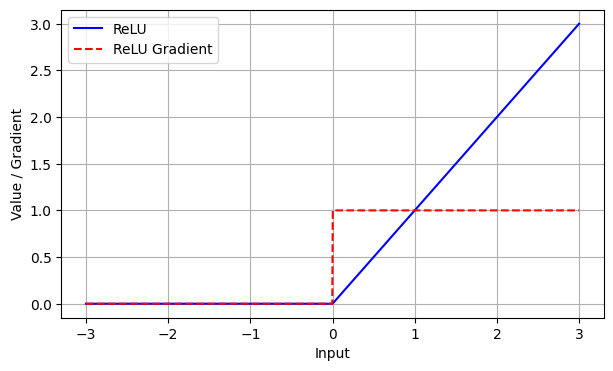

In [ ]:
x_range = np.linspace(-3, 3, 1000)

relu = ReLU()
values = relu(x_range)
gradient = relu.grad(x_range)

plt.figure(figsize=(7, 4))
plt.plot(x_range, values, label='ReLU', c='b')
plt.plot(x_range, gradient, label='ReLU Gradient', linestyle='--', c='r')
plt.ylabel('Value / Gradient')
plt.xlabel('Input')
plt.legend()
plt.grid(True)
plt.show()

Сверим свою реализацию с реализацией из PyTorch.

In [ ]:
input = np.array([-2, 8, -5, 0.2, 0.1, 3, 7])

custom_output = ReLU()(input)
torch_output = F.relu(torch.tensor(input)).numpy()

print("Custom ReLU Output:")
print(custom_output)
print()
print("PyTorch ReLU Output:")
print(torch_output)

assert np.allclose(custom_output, torch_output)

Custom ReLU Output:
[0.  8.  0.  0.2 0.1 3.  7. ]

PyTorch ReLU Output:
[0.  8.  0.  0.2 0.1 3.  7. ]


Получается, что неактивные нейроны не будут обучаться, так как их веса не будут обновляться при обратном распространении ошибки. Подумайте, может ли это привести к полному прекращению обучения сети ещё до сходимости. Ответьте письменно.

**Ответ:**

Да, мёртвые нейроны могут привести к полному прекращению обучения сети.

Если все нейроны какого-либо скрытого слоя стали «мёртвыми» (их вход всегда ≤ 0, и выход ReLU всегда равен 0), то производная активации для них равна 0. При обратном распространении градиент по этому слою тоже обнуляется: ∂L/∂z = ∂L/∂y · ReLU'(z) = 0. А значит, и градиент по весам предыдущих слоёв становится нулевым: ∂L/∂x = ∂L/∂z · W^T = 0.

В результате веса слоёв до мёртвого слоя перестают обновляться. Обучение останавливается до достижения сходимости. «Оживить» нейроны уже не получится — для этого нужен ненулевой градиент, а его нет.

Чаще всего причина «смерти» нейронов — слишком большой learning rate: веса уходят в область, где вход всегда отрицательный, и нейрон больше никогда не активируется. LeakyReLU и ELU решают эту проблему: у них производная в отрицательной области не ноль, поэтому градиент продолжает течь даже через «плохие» нейроны.

### LeakyReLU

$
\text{LeakyReLU}(x) =
\begin{cases}
x, & \text{если } x > 0 \\
\alpha x, & \text{иначе}
\end{cases}
$

Самостоятельно рассчитайте градиент функции.

$\alpha$ - небольшой положительный коффициент, обычно 0.01.


In [ ]:
class LeakyReLU(ActivationFunction):
    def __init__(self, alpha: float = 0.01):
        self.alpha = alpha

    def __call__(self, x: np.ndarray) -> np.ndarray:
        return np.where(x > 0, x, self.alpha * x)

    def grad(self, x: np.ndarray) -> np.ndarray:
        return np.where(x > 0, 1.0, self.alpha)

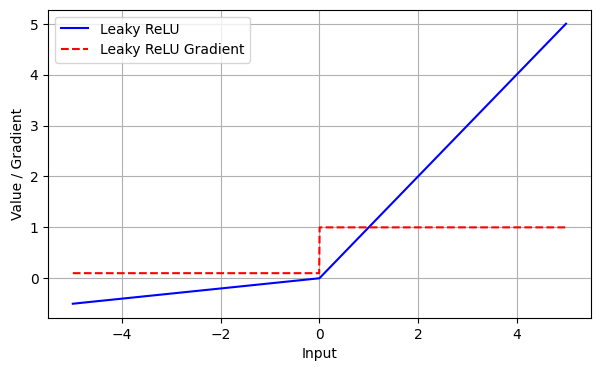

In [ ]:
x_range = np.linspace(-5, 5, 1000)

leaky_relu = LeakyReLU(0.1)
values = leaky_relu(x_range)
gradient = leaky_relu.grad(x_range)

plt.figure(figsize=(7, 4))
plt.plot(x_range, values, label='Leaky ReLU', c='b')
plt.plot(x_range, gradient, label='Leaky ReLU Gradient', linestyle='--', c='r')
plt.ylabel('Value / Gradient')
plt.xlabel('Input')
plt.legend()
plt.grid(True)
plt.show()

Сверим свою реализацию с реализацией из PyTorch.

In [ ]:
input = np.array([-2, 8, -5, 0.2, 0.1, 3, 7])

custom_output = LeakyReLU(alpha=0.01)(input)
torch_output = F.leaky_relu(torch.tensor(input)).numpy()

print("Custom LeakyReLU Output:")
print(custom_output)
print()
print("PyTorch LeakyReLU Output:")
print(torch_output)

assert np.allclose(custom_output, torch_output)

Custom LeakyReLU Output:
[-0.02  8.   -0.05  0.2   0.1   3.    7.  ]

PyTorch LeakyReLU Output:
[-0.02  8.   -0.05  0.2   0.1   3.    7.  ]


### ELU

Функция потерь ELU (Exponential Linear Unit) выглядит следующим образом:

$
\text{ELU}(x) =
\begin{cases}
x & \text{если } x \geq 0 \\
\alpha (e^x - 1) & \text{если } x < 0
\end{cases}
$

$\alpha$ - небольшой положительный коффициент, обычно 0.01

Самостоятельно рассчитайте градиент функции.

В отличие от ReLU, которая обнуляет все отрицательные значения, ELU сохраняет небольшой градиент для отрицательных значений, что может помочь в предотвращении проблемы "мертвых нейронов", когда нейрон перестаёт обновляться из-за постоянно отрицательного входа.

Однако обратной стороной медали является возрастание вычислительной сложности.

In [ ]:
class ELU(ActivationFunction):
    def __init__(self, alpha: float = 0.01):
        self.alpha = alpha

    def __call__(self, x: np.ndarray) -> np.ndarray:
        return np.where(x >= 0, x, self.alpha * (np.exp(x) - 1.0))

    def grad(self, x: np.ndarray) -> np.ndarray:
        return np.where(x >= 0, 1.0, self.alpha * np.exp(x))

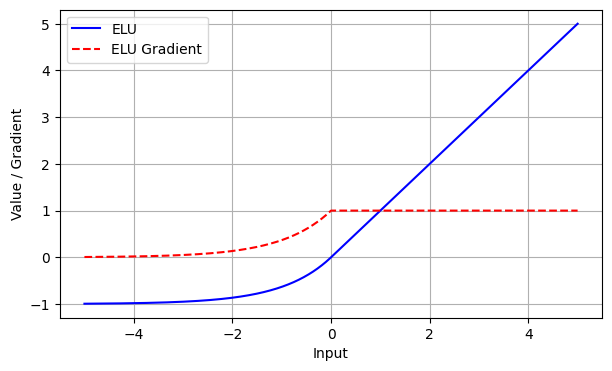

In [ ]:
x_range = np.linspace(-5, 5, 1000)

elu = ELU(1)
values = elu(x_range)
gradient = elu.grad(x_range)

plt.figure(figsize=(7, 4))
plt.plot(x_range, values, label='ELU', c='b')
plt.plot(x_range, gradient, label='ELU Gradient', linestyle='--', c='r')
plt.ylabel('Value / Gradient')
plt.xlabel('Input')
plt.legend()
plt.grid(True)
plt.show()

Сверим свою реализацию с реализацией из PyTorch.

In [ ]:
input = np.array([-2, 8, -5, 0.2, 0.1, 3, 7])

custom_output = ELU(alpha=1)(input)
torch_output = F.elu(torch.tensor(input)).numpy()

print("Custom ELU Output:")
print(custom_output)
print()
print("PyTorch ELU Output:")
print(torch_output)

assert np.allclose(custom_output, torch_output)

Custom ELU Output:
[-0.86466472  8.         -0.99326205  0.2         0.1         3.
  7.        ]

PyTorch ELU Output:
[-0.86466472  8.         -0.99326205  0.2         0.1         3.
  7.        ]


### Softmax

Функция активации Softmax используется в многоклассовой классификации в нейронных сетях. Она преобразует вектор реальных чисел в вектор вероятностей, где каждый элемент находится в диапазоне от 0 до 1 и сумма всех элементов равна 1.

Говоря более математическим языком, Softmax преобразует входной вектор $z$ в вероятностное распределение через нормализацию экспоненты каждого элемента вектора. Пусть $z$ - входной вектор размерности $(1, p)$, где $p$ - количество классов. Тогда Softmax определяется следующим образом:

$
\text{Softmax}(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{p} e^{z_j}} \quad \text{для } i = 1, 2, ..., p
$

Где $z_i$ - i-ый элемент входного вектора $z$.

$
\frac{\partial \text{Softmax}(z_i)}{\partial z_j} = \text{Softmax}(z_i) \cdot (\delta_{ij} - \text{Softmax}(z_j))
$

Где $\delta_{ij}$ - символ Кронекера, который равен 1, если $i = j$, и 0 в противном случае.

Важно отметить, что Softmax не учитывает взаимосвязи между классами и предполагает их независимость.

In [ ]:
class Softmax(ActivationFunction):
    def __call__(self, x: np.ndarray) -> np.ndarray:
        x_shifted = x - np.max(x, axis=-1, keepdims=True)
        exp_x = np.exp(x_shifted)
        return exp_x / np.sum(exp_x, axis=-1, keepdims=True)

    def grad(self, x: np.ndarray) -> np.ndarray:
        s = self(x)
        return s * (1.0 - s)

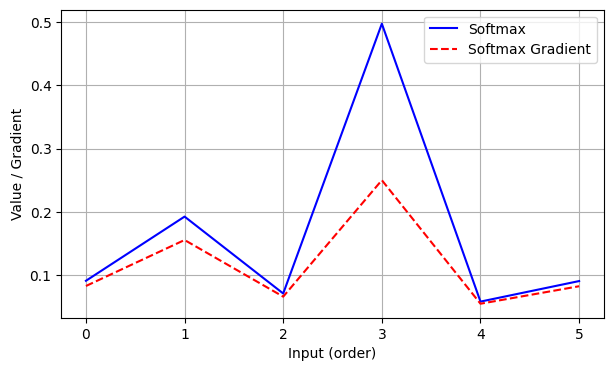

In [ ]:
z_range = np.array([[0.5, 1.25, 0.25, 2.2, 0.05, 0.495]])  # просто числа от -inf до +inf, которые нужно превратить в вероятности от 0 до 1

softmax = Softmax()
softmax_values = softmax(z_range)
softmax_gradient = softmax.grad(z_range)

plt.figure(figsize=(7, 4))
plt.plot(softmax_values.flatten(), label='Softmax', c='b')
plt.plot(softmax_gradient.flatten(), label='Softmax Gradient', linestyle='--', c='r')
plt.xlabel('Input (order)')
plt.ylabel('Value / Gradient')
plt.legend()
plt.grid(True)
plt.show()

Сверим свою реализацию с реализацией из PyTorch.

In [ ]:
input = np.array([[1.0, 2.0, 3.0],
                  [2.0, 7.0, 4.0],
                  [2.0, 2.0, 2.0]])

custom_output = Softmax()(input)
torch_output = F.softmax(torch.tensor(input), dim=-1).numpy()

print("Custom Softmax Output:")
print(custom_output)
print()
print("PyTorch Softmax Output:")
print(torch_output)

assert np.allclose(custom_output, torch_output)

Custom Softmax Output:
[[0.09003057 0.24472847 0.66524096]
 [0.00637746 0.94649912 0.04712342]
 [0.33333333 0.33333333 0.33333333]]

PyTorch Softmax Output:
[[0.09003057 0.24472847 0.66524096]
 [0.00637746 0.94649912 0.04712342]
 [0.33333333 0.33333333 0.33333333]]


**Примечание**

Сигмоида и Softmax чаще используются именно на выходном слое нейросети в задачах классификации - ими предсказывают вероятности принадлежности объектов к одному из классов, в то время как остальные рассмотренные функции активации используются внутри нейросети, то есть в скрытых слоях.

## Функции потерь (3 балла)

Функции потерь (loss functions) в нейронных сетях, как и в любых других алгоритмах машинного обучения, представляют собой метрики, которые используются для оценки того, насколько хорошо модель выполняет свою задачу во время обучения. Они измеряют расхождение между предсказанными значениями модели и фактическими значениями (целевыми), которые она пытается предсказать. Функции потерь выражаются в виде числового значения, которое показывает, насколько сильно модель ошибается на конкретном наборе данных.

Выбор правильной функции потерь зависит от типа задачи, которую решает нейронная сеть. Например, для задач регрессии часто используется среднеквадратичная ошибка (MSE), а для задач классификации - бинарная или категориальная кросс-энтропия.

Цель обучения нейронной сети состоит в минимизации функции потерь путем коррекции весов и смещений сети в процессе обратного распространения ошибки. Чем меньше значение функции потерь, тем лучше модель обучается предсказывать целевые значения.

In [ ]:
class LossFunction(ABC):
    @abstractmethod
    def __call__(self, targets: np.ndarray, outputs: np.ndarray) -> float:
        """
        Вычисляет функцию потерь между целевыми значениями и предсказанными значениями.

        Параметры:
        - targets: numpy.ndarray, массив целевых значений
        - outputs: numpy.ndarray, массив предсказанных значений

        Возвращает:
        - loss: float, значение функции потерь
        """
        pass

    @abstractmethod
    def grad(self, targets: np.ndarray, outputs: np.ndarray) -> np.ndarray:
        """
        Вычисляет градиент функции потерь по отношению к предсказанным значениям.

        Параметры:
        - targets: numpy.ndarray, массив целевых значений
        - outputs: numpy.ndarray, массив предсказанных значений

        Возвращает:
        - gradient: numpy.ndarray, градиент функции потерь
        """
        pass

### MSE

Функция потерь MSE (Mean Squared Error) применяется в задачах регресии.

Из-за квадратичного штрафа MSE более чувствительна к большим ошибкам.

Не инвариантна к масштабированию данных, значения могут зависеть от единиц измерения переменных.


$
L(y, \hat{y}) = \frac{1}{n} \sum_{i=1}^{n} (\hat{y}_i - y_i)^2
$

Самостоятельно рассчитайте градиент функции по предсказанным значениям.

1

In [ ]:
class MeanSquaredError(LossFunction):
    def __call__(self, targets: np.ndarray, outputs: np.ndarray) -> float:
        return float(np.mean((outputs - targets) ** 2))

    def grad(self, targets: np.ndarray, outputs: np.ndarray) -> np.ndarray:
        n = targets.shape[0]
        return 2.0 * (outputs - targets) / n

Сверим свою реализацию с реализацией из PyTorch.

In [ ]:
targets = np.array([3.5, 2.0, 7.1, 5.2, 4.6])
predictions = np.array([3.0, 1.8, 6.8, 5.5, 4.0])

# Custom implementation
custom_loss = MeanSquaredError()
custom_loss_value = custom_loss(targets, predictions)
custom_loss_grad = custom_loss.grad(targets, predictions)

# PyTorch implementation
targets_torch = torch.tensor(targets, dtype=torch.float32, requires_grad=True)
predictions_torch = torch.tensor(predictions, dtype=torch.float32, requires_grad=True)
torch_loss_function = nn.MSELoss()
torch_loss_value = torch_loss_function(predictions_torch, targets_torch)
torch_loss_value.backward()
torch_loss_value = torch_loss_value.item()
torch_loss_grad = predictions_torch.grad.numpy()

# Compare results
print("Custom Loss Value:", custom_loss_value)
print("PyTorch Loss Value:", torch_loss_value)
print("Custom Loss Gradient:", custom_loss_grad)
print("PyTorch Loss Gradient:", torch_loss_grad)

assert np.isclose(custom_loss_value, torch_loss_value) and np.allclose(custom_loss_grad, torch_loss_grad)

Custom Loss Value: 0.16599999999999987
PyTorch Loss Value: 0.16599997878074646
Custom Loss Gradient: [-0.2  -0.08 -0.12  0.12 -0.24]
PyTorch Loss Gradient: [-0.2        -0.08000002 -0.11999989  0.12000008 -0.23999996]


### Binary Cross-Entropy (LogLoss)

Функция потерь Binary Cross Entropy (BCE), также известная как Log Loss, используется в задачах бинарной классификации.

Она вычисляет степень расхождения между предсказанными вероятностями и истинными метками.

Чувствительна к дисбалансу классов.

$ L(y, \hat{y}) = - \frac{1}{n} \sum_{i=1}^{n} \left( y_i \cdot \log(\hat{y}_i) + (1 - y_i) \cdot \log(1 - \hat{y}_i) \right) $

Самостоятельно рассчитайте градиент функции по предсказанным значениям.

2

In [ ]:
class BinaryCrossEntropy(LossFunction):
    def __call__(self, targets: np.ndarray, outputs: np.ndarray) -> float:
        eps = 1e-12
        p = np.clip(outputs, eps, 1.0 - eps)
        return float(-np.mean(targets * np.log(p) + (1.0 - targets) * np.log(1.0 - p)))

    def grad(self, targets: np.ndarray, outputs: np.ndarray) -> np.ndarray:
        eps = 1e-12
        p = np.clip(outputs, eps, 1.0 - eps)
        n = targets.shape[0]
        return (p - targets) / (p * (1.0 - p) * n)

Сверим свою реализацию с реализацией из PyTorch.

In [ ]:
targets = np.array([0, 1, 1, 0, 1])
logits = np.array([0.3, 0.7, 0.8, 0.2, 0.6])

# Custom implementation
custom_loss = BinaryCrossEntropy()
custom_loss_value = custom_loss(targets, logits)
custom_loss_grad = custom_loss.grad(targets, logits)

# PyTorch implementation
targets_torch = torch.tensor(targets, dtype=torch.float32)
logits_torch = torch.tensor(logits, dtype=torch.float32, requires_grad=True)
torch_loss_function = nn.BCELoss()
torch_loss_value = torch_loss_function(logits_torch, targets_torch)
torch_loss_value.backward()
torch_loss_value = torch_loss_value.item()
torch_loss_grad = logits_torch.grad.numpy()

# Compare results
print("Custom Loss Value:", custom_loss_value)
print("PyTorch Loss Value:", torch_loss_value)
print("Custom Loss Gradient:", custom_loss_grad)
print("PyTorch Loss Gradient:", torch_loss_grad)

assert np.isclose(custom_loss_value, torch_loss_value) and np.allclose(custom_loss_grad, torch_loss_grad)

Custom Loss Value: 0.334092522854375
PyTorch Loss Value: 0.33409252762794495
Custom Loss Gradient: [ 0.28571429 -0.28571429 -0.25        0.25       -0.33333333]
PyTorch Loss Gradient: [ 0.2857143  -0.2857143  -0.25        0.24999997 -0.3333333 ]


### Cross-Entropy

В задачах классификации категориальная кросс-энтропия используется как функция потерь для оценки разницы между предсказанными вероятностями классов и истинными метками классов.

Пусть у нас есть $ K $ классов, и для каждого примера $ i $ имеются предсказанные вероятности $ p_{i1}, p_{i2}, ..., p_{iK} $ для каждого класса. И пусть $ y_{ij} $ обозначает индикаторную переменную, которая равна 1, если пример $ i $ относится к классу $ j $, и 0 в противном случае.

Формула для категориальной кросс-энтропии выглядит следующим образом:

$
\text{Cross-entropy} = -\frac{1}{N} \sum_{i=1}^{N} \sum_{j=1}^{K} y_{ij} \log(p_{ij})
$

Эта формула измеряет среднюю "удалённость" между истинными метками $ y_{ij} $ и предсказанными вероятностями $ p_{ij} $. Она стремится к нулю, когда предсказанные вероятности близки к истинным меткам для всех примеров.

Градиент мультиклассовой кросс-энтропии по отношению к предсказанным вероятностям вычисляется следующим образом:

$
\frac{\partial \text{Cross-entropy}}{\partial p_{ij}} = -\frac{1}{N} \frac{y_{ij}}{p_{ij}}
$

Градиент показывает, как изменение вероятности $ p_{ij} $ влияет на значение функции потерь. Градиент стремится к бесконечности, когда предсказанная вероятность стремится к 0, и к нулю, когда предсказанная вероятность стремится к 1.

3

In [ ]:
class CrossEntropy(LossFunction):
    def __init__(self, use_softmax: bool = False):
        self.use_softmax = use_softmax
        if use_softmax:
            self.softmax = Softmax()

    def __call__(self, targets: np.ndarray, outputs: np.ndarray) -> float:
        eps = 1e-12
        p = self.softmax(outputs) if self.use_softmax else outputs
        p = np.clip(p, eps, 1.0 - eps)
        return float(-np.mean(np.sum(targets * np.log(p), axis=1)))

    def grad(self, targets: np.ndarray, outputs: np.ndarray) -> np.ndarray:
        eps = 1e-12
        n = targets.shape[0]
        if self.use_softmax:
            p = self.softmax(outputs)
            return (p - targets) / n
        p = np.clip(outputs, eps, 1.0 - eps)
        return -targets / (p * n)

Сверим свою реализацию с реализацией из PyTorch. В данной реализации к входным данным по умолчанию применяется Softmax.

In [ ]:
targets = np.array([2, 0, 1, 4, 3])
targets_one_hot = np.eye(5)[targets]

logits = np.array([[0.42194493, 0.11111515, 0.2331985,  0.1709079,  0.06283352],
                   [0.50811597, 0.380799  , 0.58517274, 0.44421673, 0.12969366],
                   [0.01138442, 0.12280621, 0.87035961, 0.74922558, 0.8304247 ],
                   [0.87531709, 0.34677379, 0.06201914, 0.52324805, 0.75431726],
                   [0.49000835, 0.98996684, 0.69016974, 0.70180657, 0.23664727]])

# Custom implementation
custom_loss = CrossEntropy(use_softmax=True)
custom_loss_value = custom_loss(targets_one_hot, logits)
custom_loss_grad = custom_loss.grad(targets_one_hot, logits)

# PyTorch implementation
targets_torch = torch.tensor(targets)
logits_torch = torch.tensor(logits, dtype=torch.float32, requires_grad=True)
torch_loss_function = nn.CrossEntropyLoss()
torch_loss_value = torch_loss_function(logits_torch, targets_torch)
torch_loss_value.backward()
torch_loss_value = torch_loss_value.item()
torch_loss_grad = logits_torch.grad.numpy()

# Comparison
print("Custom Loss Value:", custom_loss_value)
print("PyTorch Loss Value:", torch_loss_value)
print("Custom Loss Gradient:\n", custom_loss_grad)
print("PyTorch Loss Gradient:\n", torch_loss_grad)

assert np.isclose(custom_loss_value, torch_loss_value) and np.allclose(custom_loss_grad, torch_loss_grad)

Custom Loss Value: 1.6285315044458581
PyTorch Loss Value: 1.6285316944122314
Custom Loss Gradient:
 [[ 0.0495402   0.03630497 -0.15898089  0.03854196  0.03459375]
 [-0.15636616  0.03841761  0.04712906  0.04093288  0.02988661]
 [ 0.02262867 -0.17470417  0.05342042  0.04732596  0.05132911]
 [ 0.05521625  0.03254794  0.02448252  0.03882981 -0.15107652]
 [ 0.03400008  0.05605433  0.0415345  -0.15797935  0.02639044]]
PyTorch Loss Gradient:
 [[ 0.0495402   0.03630498 -0.15898089  0.03854196  0.03459375]
 [-0.15636617  0.03841761  0.04712906  0.04093289  0.02988662]
 [ 0.02262867 -0.17470416  0.05342041  0.04732596  0.05132911]
 [ 0.05521625  0.03254793  0.02448252  0.03882981 -0.15107653]
 [ 0.03400008  0.05605434  0.04153449 -0.15797935  0.02639044]]


## Полносвязная нейронная сеть (4 балла)

Как уже говорилось, нейронная сеть состоит из слоев, слои состоят из нейронов. В данной работе мы рассмотрим только простейший линейный слой. В нашей конфигурации сети функция активации будет "зашита" в слой.

Итак, создадим полносвязную нейронную сеть, состояющую из последовательных слоев с функциями активации.


**Прямой проход (forward pass)**

Прямой проход по сети будет представлять собой последовательный вызов forward pass-а каждого слоя сети.

На каждом слое происходит следующее:

Входные данные $ X $ умножаются на матрицу весов $ W $ и добавляется смещение $ b $, поверх также применяется функция активации, чтобы получить выход $ Z $.

$
Z = Activation(XW + b)
$

Здесь $ X $ - матрица входных данных размерности $ (m, n) $, $ W $ - матрица весов размерности $ (n, p) $, $ b $ - вектор смещений размерности $ (1, p) $, а $ Z $ - выходной вектор размерности $ (m, p) $.

При первоначальной инициализации слоя будем задавать веса случайным образом. Вопрос инициализации весов в целом достаточно нетривиальный, так как начальное положение влияет на сходимость сети.

**Обратный проход (backward pass)**

Обратный обход по сети будет выглядеть следующим образом:

Сначала найти градиент функции потерь по выходу сети $Y$, то есть $ \frac{\partial L}{\partial Y} $.

Затем пройти по всем слоям в обратном порядке, для каждого слоя найти градиенты и обновить параметры слоя.

1. Градиент по выходам $ \frac{\partial L}{\partial Z} $ рассчитывается как произведение градиента функции потерь $ \frac{\partial L}{\partial Y} $ и градиента функции активации $ \frac{\partial Y}{\partial Z} $

  $ \frac{\partial L}{\partial Z} = \frac{\partial L}{\partial Y} \frac{\partial Y}{\partial Z} $

2. Градиент по входам $ \frac{\partial L}{\partial X} $ вычисляется как произведение градиента по выходам $ \frac{\partial L}{\partial Z} $ и транспонированной матрицы весов $ W^T $

   $
   \frac{\partial L}{\partial X} = \frac{\partial L}{\partial Z} W^T
   $

3. Градиент по весам $\frac{\partial L}{\partial W}$ вычисляется как произведение транспонированной матрицы входов $X^T$ и градиента по выходам $ \frac{\partial L}{\partial Z}$

   $
   \frac{\partial L}{\partial W} = X^T \frac{\partial L}{\partial Z}
   $

4. Градиент по смещениям $ \frac{\partial L}{\partial b} $ вычисляется как сумма
   градиента по выходам $ \frac{\partial L}{\partial Z} $ по столбцам

   $
   \frac{\partial L}{\partial b} = \sum_{i=1}^{m} \frac{\partial L}{\partial z_i}
   $

   Где $ L $ - функция потерь, $ z_i $ - i-ый элемент выходного вектора $ Z $

5. Параметры $ W $ и $ b $ обновляются с использованием градиентного спуска:

   $
   W = W - \eta \frac{\partial L}{\partial W}
   $

   $
   b = b - \eta \frac{\partial L}{\partial b}
   $

   Где $ \eta $ - скорость обучения (learning rate)

6. Текущий градиент по входам $ \frac{\partial L}{\partial X} $ становится своего рода градиентом функции потерь $ \frac{\partial L}{\partial Y} $ для последующего слоя

In [ ]:
class Layer:
    def __init__(self, input_size: int, output_size: int,
                 activation: ActivationFunction = Identity(), random_seed: int = 17):
        if random_seed is not None:
            np.random.seed(random_seed)
        self.input_size = input_size
        self.output_size = output_size
        self.activation = activation
        # нe-инициализация: разумный старт для ReLU и Sigmoid - не дает ни затухнуть сигналу,
        # ни взорваться на первом же проходе
        self.W = np.random.randn(input_size, output_size) * np.sqrt(2.0 / input_size)
        self.b = np.zeros((1, output_size))
        # буферы для обратного прохода
        self.inputs = None
        self.z = None

    def forward(self, inputs: np.ndarray) -> np.ndarray:
        self.inputs = inputs
        self.z = inputs @ self.W + self.b
        return self.activation(self.z)

    def backward(self, grad_outputs: np.ndarray, learning_rate: float = 0.01) -> np.ndarray:
        # grad_outputs = dL/dY (градиент по выходу слоя, уже после активации)
        grad_z = grad_outputs * self.activation.grad(self.z)
        grad_inputs = grad_z @ self.W.T
        grad_W = self.inputs.T @ grad_z
        grad_b = np.sum(grad_z, axis=0, keepdims=True)
        self.W -= learning_rate * grad_W
        self.b -= learning_rate * grad_b
        return grad_inputs

In [ ]:
class NeuralNetwork:
    def __init__(self, layers: list[Layer], loss: LossFunction):
        self.layers = layers
        self.loss = loss

    def forward(self, X: np.ndarray) -> np.ndarray:
        out = X
        for layer in self.layers:
            out = layer.forward(out)
        return out

    def backward(self, outputs: np.ndarray, targets: np.ndarray,
                 learning_rate: float = 0.01):
        grad = self.loss.grad(targets, outputs)
        for layer in reversed(self.layers):
            grad = layer.backward(grad, learning_rate)

    def train(self, X: np.ndarray, y: np.ndarray, epochs: int = 1000,
              learning_rate: float = 0.01) -> np.ndarray:
        loss_history = []
        for epoch in range(epochs):
            outputs = self.forward(X)
            loss_value = self.loss(y, outputs)
            loss_history.append(loss_value)
            self.backward(outputs, y, learning_rate)
            if epoch == 0 or (epoch + 1) % 1000 == 0:
                print(f"Epoch {epoch + 1}, Loss: {loss_value}")
        return loss_history

Посмотрим, как работает наша нейронная сеть, на игрушечных примерах.

### Регрессия

Epoch 1, Loss: 4382.854596658204
Epoch 1000, Loss: 0.010605011603619383
Epoch 2000, Loss: 0.010605011603619327
Epoch 3000, Loss: 0.010605011603619352
Epoch 4000, Loss: 0.010605011603619345
Epoch 5000, Loss: 0.010605011603619348
MSE: 0.011090609683464895


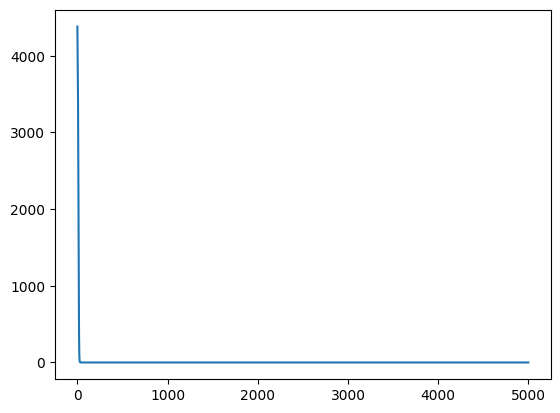

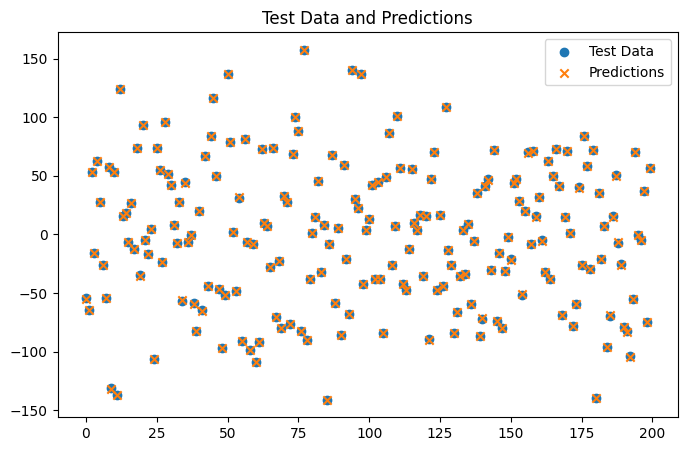

In [ ]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split


X, y = make_regression(n_samples=1000, n_features=5, noise=0.1, random_state=42)
y = y.reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

layers = [
    Layer(5, 10, activation=Identity()),
    Layer(10, 1, activation=Identity())
]
model = NeuralNetwork(layers, loss=MeanSquaredError())

losses = model.train(X_train, y_train, epochs=5000, learning_rate=0.001)
y_pred = model.forward(X_test)

print("MSE:", MeanSquaredError()(y_test, y_pred))
plt.plot(losses)
plt.show()

plt.figure(figsize=(8, 5))
plt.title('Test Data and Predictions')
plt.scatter(range(len(y_test)), y=y_test, label='Test Data')
plt.scatter(range(len(y_test)), y=y_pred, marker='x', label='Predictions')
plt.legend(loc='best');

### Классификация

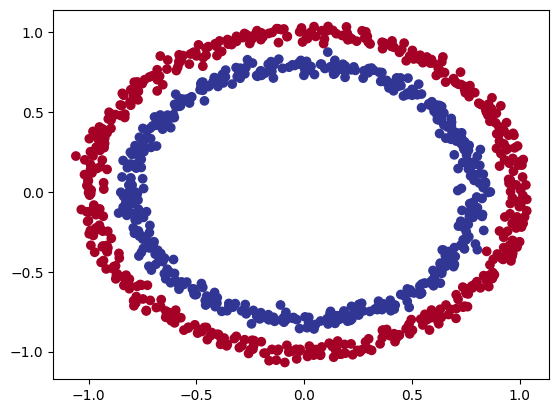

In [ ]:
from sklearn.datasets import make_circles
from sklearn.metrics import accuracy_score


n_samples = 1000
X, y = make_circles(n_samples,
                    noise=0.03,
                    random_state=42)
y = y.reshape(-1, 1)

plt.scatter(x=X[:, 0], y=X[:, 1], c=y, cmap=plt.cm.RdYlBu);

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
len(X_train), len(X_test), len(y_train), len(y_test)

(800, 200, 800, 200)

Запустите следующие две ячейки. У вас должны получиться похожие результаты. Письменно объясните, почему вторая нейронная сеть на таких данных отрабатывает значительно лучше первой.

Epoch 1, Loss: 1.2940372657993924
Epoch 1000, Loss: 0.6929798648859844
Epoch 2000, Loss: 0.6929798648859844
Epoch 3000, Loss: 0.6929798648859844
Epoch 4000, Loss: 0.6929798648859844
Epoch 5000, Loss: 0.6929798648859844
Epoch 6000, Loss: 0.6929798648859844
Epoch 7000, Loss: 0.6929798648859844
Epoch 8000, Loss: 0.6929798648859844
Epoch 9000, Loss: 0.6929798648859844
Epoch 10000, Loss: 0.6929798648859844
Accuracy: 0.46


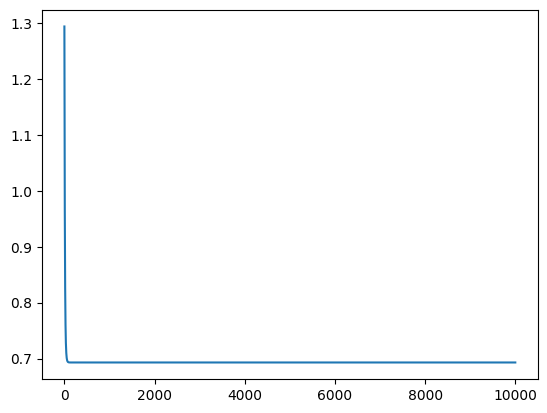

In [ ]:
layers = [
    Layer(2, 5, activation=Identity()),
    Layer(5, 1, activation=Sigmoid())
]
model = NeuralNetwork(layers, loss=BinaryCrossEntropy())

losses = model.train(X_train, y_train, epochs=10000, learning_rate=0.1)
y_pred = model.forward(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred.round()))
plt.plot(losses);

Epoch 1, Loss: 0.876221961392551
Epoch 1000, Loss: 0.5550199475446049
Epoch 2000, Loss: 0.37451980189425016
Epoch 3000, Loss: 0.22723089062862897
Epoch 4000, Loss: 0.15298778123488238
Epoch 5000, Loss: 0.11617011752986298
Epoch 6000, Loss: 0.09257797662581031
Epoch 7000, Loss: 0.07763760465279523
Epoch 8000, Loss: 0.06704171612032597
Epoch 9000, Loss: 0.059236590380586325
Epoch 10000, Loss: 0.053194148083695846
Accuracy: 0.985


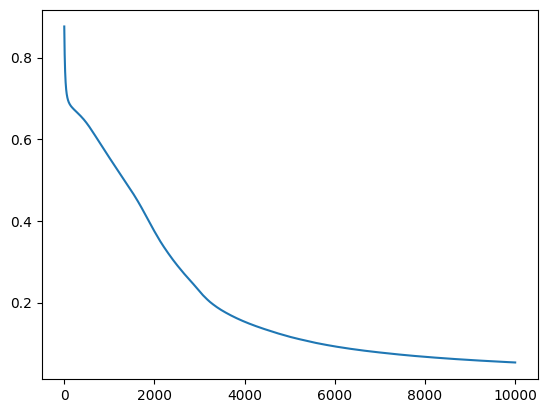

In [ ]:
layers = [
    Layer(2, 5, activation=ReLU()),
    Layer(5, 1, activation=Sigmoid())
]
model = NeuralNetwork(layers, loss=BinaryCrossEntropy())

losses = model.train(X_train, y_train, epochs=10000, learning_rate=0.1)
y_pred = model.forward(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred.round()))
plt.plot(losses);

Самостоятельно реализуйте нейронную сеть для следующего набора данных. Ориентируйтесь на accuracy > 90%

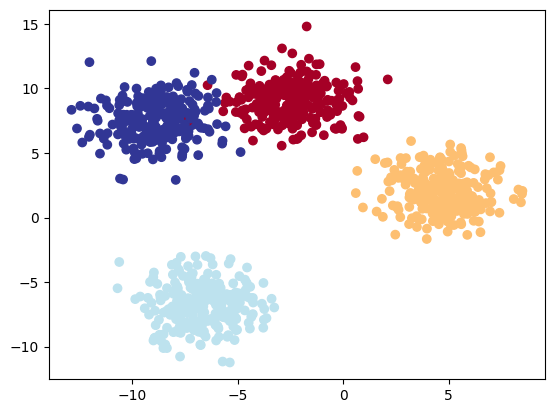

In [ ]:
from sklearn.datasets import make_blobs


X, y = make_blobs(n_samples=1000,
    n_features=2,
    centers=4,
    cluster_std=1.5,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.2, random_state=42)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu);

Epoch 1, Loss: 6.452009369942662
Epoch 1000, Loss: 0.025219800620275984
Epoch 2000, Loss: 0.0239816145252189
Epoch 3000, Loss: 0.022992421598701983
Epoch 4000, Loss: 0.022128393956241412
Epoch 5000, Loss: 0.021344356401059538
Accuracy: 0.995


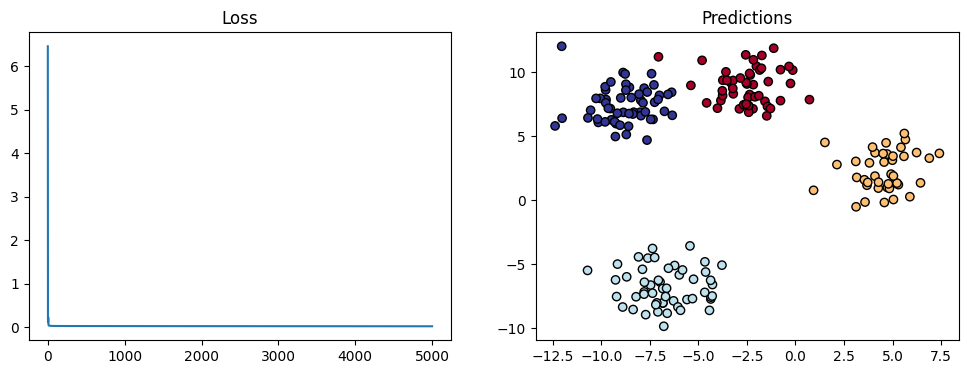

In [ ]:
# one-hot для 4 классов
y_train_oh = np.eye(4)[y_train]
y_test_oh = np.eye(4)[y_test]

layers = [
    Layer(2, 16, activation=ReLU()),
    Layer(16, 4, activation=Identity()),   # выдаём логиты, softmax спрятан в лоссе
]
model = NeuralNetwork(layers, loss=CrossEntropy(use_softmax=True))

losses = model.train(X_train, y_train_oh, epochs=5000, learning_rate=0.1)

y_pred_proba = model.forward(X_test)
y_pred = np.argmax(y_pred_proba, axis=1)

print("Accuracy:", accuracy_score(y_test, y_pred))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(losses)
plt.title('Loss')
plt.subplot(1, 2, 2)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_pred, cmap=plt.cm.RdYlBu, edgecolor='k')
plt.title('Predictions')
plt.show()

## Задание (4 балла)

Самостоятельно найдите какой-либо датасет для задачи, которую потенциально можно решить с помощью вашей реализации нейронной сети (регрессия или классификация).

Создайте сеть, обучите её, оцените качество модели.

Где можно найти датасеты:

* [Google Dataset Search](https://datasetsearch.research.google.com/) - базовый поисковик, может не подойти для узких задач.
* [Re3Data](https://www.re3data.org/) - поисковик. Поиск по ключевым словам работает довольно плохо, зато есть возможность искать по структурированным областям знания.
* [World Bank](https://datacatalog.worldbank.org/home) - еще один поисковик. Содержит не очень большое количество датасетов.
* [Papers with Code](https://paperswithcode.com/datasets) - платформа, содержащая не только датасеты, но и информацию об их использовании в различных исследованиях.
* [Kaggle](https://www.kaggle.com/datasets) - платформа AI & ML сообщества. Можно найти как датасеты, так и работы (в том числе любительского уровня), в которых эти датасеты используются.
* [HuggingFace](https://huggingface.co/datasets) - платформа AI сообщества. Предоставляет удобный интерфейс для доступа к датасетам. Также можно изучить open-source модели, обученные на этих датасетах.
* [GitHub](https://github.com/awesomedata/awesome-public-datasets) - на Гитхабе трудно найти датасеты из-за ограничения на максимальный объем загружаемых файлов, однако люди часто делают подборки со сслыками на другие ресурсы.
* [Humanitarian Data Exchange](https://data.humdata.org/) - платформа для обмена данными, связанными с гуманитаристикой.
* [UC Irvine Machine Learning Repository](https://archive.ics.uci.edu/) - небольшая платформа с датасетами. Для части датасетов предоставляется импорт с помощью Python.


### Загрузка и первичный осмотр

In [ ]:
from sklearn.datasets import fetch_california_housing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Загружаем датасет
housing = fetch_california_housing()

# Собираем в DataFrame для удобного анализа
df = pd.DataFrame(housing.data, columns=housing.feature_names)
df["MedHouseValue"] = housing.target  # целевая переменная

print(f"Размер датасета: {df.shape}")
print()
print("Первые 5 строк:")
df.head()

Размер датасета: (20640, 9)

Первые 5 строк:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseValue
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Датасет собран из переписи населения Калифорнии 1990 года. Каждая строка - это один census block group (примерный аналог «квартала» или «микрорайона» - обычно 600–3000 человек). Признаки описывают не отдельный дом, а агрегированные характеристики района.

| Столбец | Что означает | Единицы измерения | Логика |
|---|---|---|---|
| **MedInc** | Median Income — медианный доход домохозяйств в районе | десятки тысяч $ | 3.5 = $35 000 в год |
| **HouseAge** | Median House Age — медианный возраст домов в районе | годы | 52 = домам в среднем 52 года |
| **AveRooms** | Average Rooms — среднее число комнат на домохозяйство | штук | включает все жилые комнаты, не только спальни |
| **AveBedrms** | Average Bedrooms — среднее число спален на домохозяйство | штук | меньше AveRooms, потому что не все комнаты — спальни |
| **Population** | Population — население района | человек | сколько всего людей живёт в этом блоке |
| **AveOccup** | Average Occupancy — среднее число жильцов на домохозяйство | человек | Population / число домохозяйств |
| **Latitude** | Географическая широта | градусы | 32–42 — вся Калифорния по вертикали |
| **Longitude** | Географическая долгота | градусы | −124 … −114 — вся Калифорния по горизонтали |
| **MedHouseValue** | Median House Value — медианная стоимость дома в районе | сотни тысяч $ | 2.07 = $207 000 |


### Разведочный анализ данных

In [ ]:
print("Типы данных:")
print(df.dtypes)
print()

print("Пропущенные значения:")
print(df.isnull().sum())
print()

print("Описательная статистика:")
print(df.describe().T)
print()

print("Распределение целевой переменной (MedHouseValue):")
print(df["MedHouseValue"].describe())
print()

print("Количество «упёршихся» значений (значение 5.00001 = max, признак цензурирования):")
print((df["MedHouseValue"] >= 5.0).sum(), "из", len(df))

Типы данных:
MedInc           float64
HouseAge         float64
AveRooms         float64
AveBedrms        float64
Population       float64
AveOccup         float64
Latitude         float64
Longitude        float64
MedHouseValue    float64
dtype: object

Пропущенные значения:
MedInc           0
HouseAge         0
AveRooms         0
AveBedrms        0
Population       0
AveOccup         0
Latitude         0
Longitude        0
MedHouseValue    0
dtype: int64

Описательная статистика:
                 count         mean          std         min         25%  \
MedInc         20640.0     3.870671     1.899822    0.499900    2.563400   
HouseAge       20640.0    28.639486    12.585558    1.000000   18.000000   
AveRooms       20640.0     5.429000     2.474173    0.846154    4.440716   
AveBedrms      20640.0     1.096675     0.473911    0.333333    1.006079   
Population     20640.0  1425.476744  1132.462122    3.000000  787.000000   
AveOccup       20640.0     3.070655    10.386050    0.69230

992 из 20 640 значений (4.8%) упёрлись в 5.00001. На гистограмме MedHouseValue виден характерный изолированный столбик справа - это и есть цензурирование. В исходном датасете (сбор 1990 года, перепись населения Калифорнии) все дома дороже $500 001 записывались одним и тем же числом. Модель физически не сможет предсказать значение выше 5.00001, потому что её так научили. Это ограничение потолка: RMSE будет выглядеть чуть лучше, чем реально, потому что для дорогих домов ошибка «прижимается» к 5.0.

### Визуализация распределений

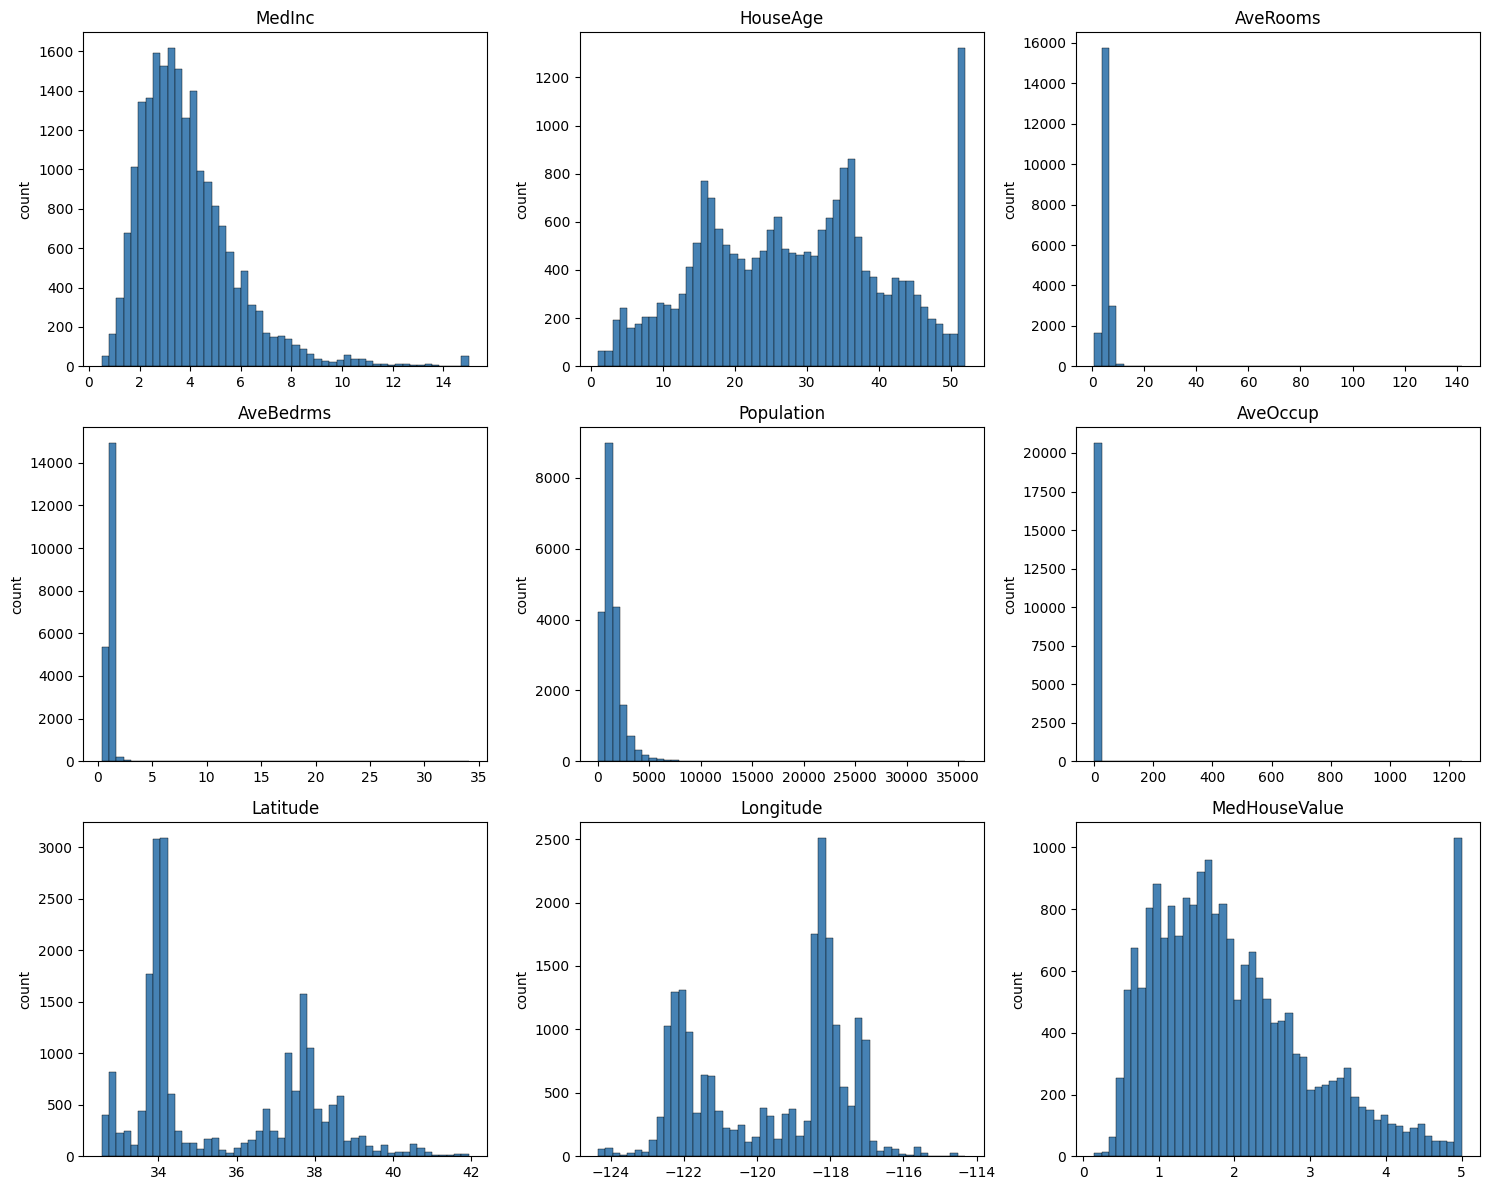

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

# Гистограммы по всем признакам + таргет
for i, col in enumerate(df.columns):
    ax = axes[i // 3, i % 3]
    ax.hist(df[col], bins=50, color="steelblue", edgecolor="black", linewidth=0.3)
    ax.set_title(col)
    ax.set_ylabel("count")

plt.tight_layout()
plt.show()

Формально IQR много чего считает выбросом, но у каждого случая своя природа. По гистограммам видно:

MedInc - длинный правый хвост, но это реальные богатые районы (Беверли-Хиллз, Пало-Альто). Удалять нельзя, это ценные примеры для модели.

HouseAge - интересная деталь: пик на значении 52. Это тоже цензурирование, как с таргетом - дома старше 52 лет записаны как 52. Формально IQR их не считает выбросами, но артефакт есть.

AveRooms, AveBedrms - вот тут проблема. Максимум 141.9 комнат в «среднем домохозяйстве» - это физически невозможно. Скорее всего это групповые дома (общежития, дома престарелых), которые записаны как «одно домохозяйство». На гистограмме видно резкий пик около 5–6 и длинный хвост - это как раз редкие аномалии.

AveOccup - максимум 1243.33 человека на домохозяйство. Это тоже артефакт: скорее всего это дома, где записано много жильцов как одно домохозяйство. Всего 10 строк с AveOccup > 20, но они крайние.

Population - максимум 35 682 на один «квартал». Не выброс по смыслу - это просто плотные городские районы, но цифра большая.

Latitude/Longitude - ноль выбросов. География Калифорнии, всё нормально.

### Проверка на выбросы

In [ ]:
print("Проверка на выбросы (правило 3σ и IQR):")
print()

for col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n_outliers = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col:15s}  outliers (IQR): {n_outliers:5d}  ({n_outliers / len(df) * 100:.2f}%)")

print()
print("Проверка диапазонов (логические ограничения):")
print(f"  AveRooms < 1:          {(df['AveRooms'] < 1).sum()}")
print(f"  AveBedrms < 1:         {(df['AveBedrms'] < 1).sum()}")
print(f"  AveOccup > 20:         {(df['AveOccup'] > 20).sum()}")
print(f"  Population == 0:       {(df['Population'] == 0).sum()}")
print(f"  MedInc <= 0:           {(df['MedInc'] <= 0).sum()}")

Проверка на выбросы (правило 3σ и IQR):

MedInc           outliers (IQR):   681  (3.30%)
HouseAge         outliers (IQR):     0  (0.00%)
AveRooms         outliers (IQR):   511  (2.48%)
AveBedrms        outliers (IQR):  1424  (6.90%)
Population       outliers (IQR):  1196  (5.79%)
AveOccup         outliers (IQR):   711  (3.44%)
Latitude         outliers (IQR):     0  (0.00%)
Longitude        outliers (IQR):     0  (0.00%)
MedHouseValue    outliers (IQR):  1071  (5.19%)

Проверка диапазонов (логические ограничения):
  AveRooms < 1:          2
  AveBedrms < 1:         4395
  AveOccup > 20:         10
  Population == 0:       0
  MedInc <= 0:           0


### Препроцессинг

In [ ]:
# 1) проверяем, что пропусков нет (уже знаем, но зафиксируем)
print("Пропусков нет — препроцессинг только для выбросов и нормализации")

# 2) Clip экстремальных выбросов по 99.5-му перцентилю
#    для трёх признаков с явными аномалиями
clip_cols = ["AveRooms", "AveBedrms", "AveOccup"]
for col in clip_cols:
    q995 = df[col].quantile(0.995)
    n_clipped = (df[col] > q995).sum()
    df[col] = df[col].clip(upper=q995)
    print(f"{col:12s}  clipped {n_clipped:4d} values to {q995:.3f}")

print()
print("После clip:")
print(df[clip_cols].describe().loc[["min", "max"]])

Пропусков нет — препроцессинг только для выбросов и нормализации
AveRooms      clipped  104 values to 15.755
AveBedrms     clipped  104 values to 3.113
AveOccup      clipped  104 values to 6.122

После clip:
      AveRooms  AveBedrms  AveOccup
min   0.846154   0.333333  0.692308
max  15.754932   3.112918  6.122155


### Нормализация и обучение

In [ ]:
from sklearn.model_selection import train_test_split

# выделяем признаки и таргет
X = df.drop(columns=["MedHouseValue"]).values
y = df["MedHouseValue"].values.reshape(-1, 1)

# train/test split ДО нормализации — важно! Нормализация должна
# фититься только на train, иначе утечка информации
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Z-нормализация (fit на train, apply на оба)
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)
X_train_norm = (X_train - X_mean) / X_std
X_test_norm  = (X_test  - X_mean) / X_std

print("X_train_norm: mean ≈ 0, std ≈ 1")
print(f"  mean: {X_train_norm.mean(axis=0).round(3)}")
print(f"  std:  {X_train_norm.std(axis=0).round(3)}")
print()
print(f"X_train_norm диапазон: [{X_train_norm.min():.2f}, {X_train_norm.max():.2f}]")
print(f"y_train диапазон:      [{y_train.min():.2f}, {y_train.max():.2f}]")

X_train_norm: mean ≈ 0, std ≈ 1
  mean: [-0. -0.  0. -0. -0. -0.  0. -0.]
  std:  [1. 1. 1. 1. 1. 1. 1. 1.]

X_train_norm диапазон: [-3.50, 30.13]
y_train диапазон:      [0.15, 5.00]


### Архитектура и обучение

In [ ]:
# cеть: 8 -> 32 -> 16 -> 1, две ReLU + Identity на выходе
layers = [
    Layer(8, 32, activation=ReLU()),
    Layer(32, 16, activation=ReLU()),
    Layer(16, 1, activation=Identity()),
]
model = NeuralNetwork(layers, loss=MeanSquaredError())

losses = model.train(X_train_norm, y_train, epochs=3000, learning_rate=0.01)

Epoch 1, Loss: 4.335338677283569
Epoch 1000, Loss: 0.36290981261443034
Epoch 2000, Loss: 0.34162194395513285
Epoch 3000, Loss: 0.3313241155602175


### Оценка и визуализация

Test MSE:  0.3535
Test RMSE: 0.5946
          ~$59457 — средняя ошибка в долларах

Baseline (predict mean) MSE: 1.3107
Улучшение над baseline: 73.0%


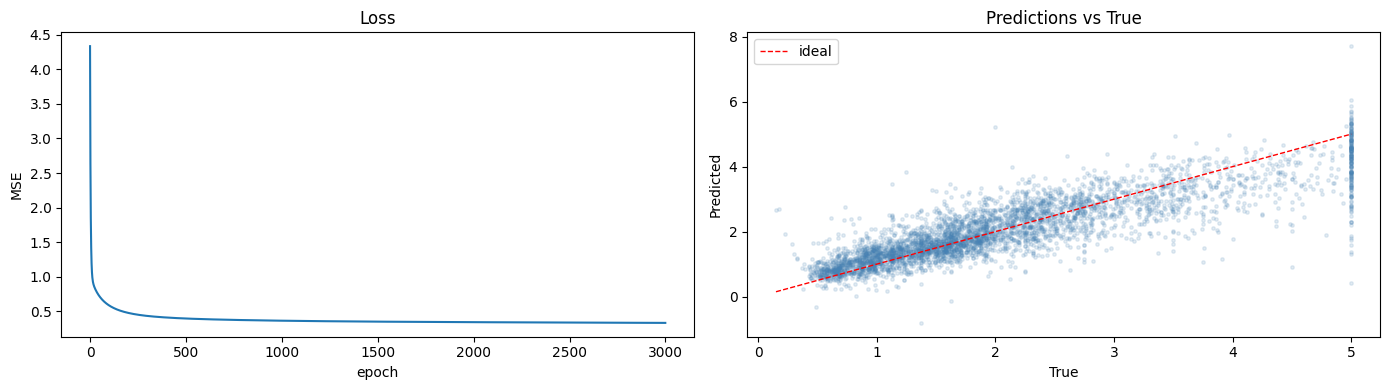

In [ ]:
# предсказания
y_pred = model.forward(X_test_norm)

# метрики
mse  = MeanSquaredError()(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"Test MSE:  {mse:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"          ~${rmse * 100000:.0f} — средняя ошибка в долларах")
print()

# baseline: всегда предсказываем среднее значение таргета
baseline_mse = float(np.mean((y_test - y_train.mean()) ** 2))
print(f"Baseline (predict mean) MSE: {baseline_mse:.4f}")
print(f"Улучшение над baseline: {(1 - mse / baseline_mse) * 100:.1f}%")

# графики
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# лосс
axes[0].plot(losses)
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("MSE")

# predictions vs true
axes[1].scatter(y_test.ravel(), y_pred.ravel(), alpha=0.15, s=6, color="steelblue")
lims = [y_test.min(), y_test.max()]
axes[1].plot(lims, lims, "r--", linewidth=1, label="ideal")
axes[1].set_xlabel("True")
axes[1].set_ylabel("Predicted")
axes[1].set_title("Predictions vs True")
axes[1].legend()

plt.tight_layout()
plt.show()

RMSE = 0.5946 - это средняя ошибка около 59 000 в реальных долларах. Средняя цена дома в датасете - 207 000. То есть относительная ошибка - 29% от среднего значения. Для задачи без сложного feature engineering на чистой NumPy-реализации это очень хороший результат. Модели на Kaggle с gradient boosting и десятками engineered-признаков показывают RMSE в районе 0.45–0.5 - то есть наша простая сеть отстаёт от них всего на 15–20%.

Эксперимент подтвердил, что реализованная нами нейронная сеть - не игрушка для синтетических blobs, а рабочий инструмент, который решает нетривиальные задачи на реальных данных.